# 01 — Data Collection
**Stage:** Validation

**TL;DR:** All 8 raw files downloaded (15.7 years of hourly grid load, 8 weather points, 365 holidays). Coverage is ≥90% in 176 of 192 months; the only serious gap is **3 Jan – 12 Jul 2023**, and the critical window **Aug–Dec 2021–2025 is ~100% complete** — the project question can be answered.

## 1. Question
Can we get **all the raw data** the project needs into `data/raw/`, and is it complete enough to answer
*"What caused Karnataka's 2023 electricity surge?"*

We need:
1. **Grid data** — hourly state load, plus generation by station, reservoirs, outages (KPTCL, via Vonter/kptcl-load-curve)
2. **Weather** — daily rain & temperature for the farm belt + Bengaluru; hourly temperature for Bengaluru (Open-Meteo)
3. **Holidays** — Karnataka public holidays (festivals change demand a lot)

## 2. Expectation *(written before running)*
- KPTCL files should cover **2011-01-01 → 2026-08-19** (seen during project research).
- I expect a **known gap: Feb–Jun 2023** in the hourly load data. Other smaller gaps are likely, because the data
  was scraped from daily Excel reports.
- Weather from Open-Meteo is a reanalysis model, so it should have **no gaps** for any date.
- Holidays: roughly **20–25 per year**.
- The critical window for our question, **Jul–Dec 2022, 2023 and 2024**, must be (nearly) complete — if it is not,
  the project has a problem.

## 3. Data used
| Source | What | Licence / credit |
|---|---|---|
| [Vonter/kptcl-load-curve](https://github.com/Vonter/kptcl-load-curve) | KPTCL daily load-curve reports parsed to Parquet | ODbL |
| [Open-Meteo archive API](https://open-meteo.com/en/docs/historical-weather-api) | ERA5-based historical weather | CC BY 4.0 |
| [`holidays` Python package](https://pypi.org/project/holidays/) | India (Karnataka) public holidays | MIT |

Weather points (from `src/config.py`): 7 farm-belt towns (Raichur, Kalaburagi, Belagavi, Mandya, Davangere,
Tumakuru, Hubballi) + Bengaluru.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import from src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, data

pd.set_option("display.width", 200)
START, END = "2011-01-01", "2026-08-19"   # KPTCL coverage

## 4. Analysis
### Step 4.1 — Download the KPTCL grid files
*Why:* this is the core dataset — 15 years of the state grid, published by KPTCL and parsed by Vonter.

In [2]:
kptcl_paths = data.download_kptcl()

  skip (exists): kptcl.parquet
  skip (exists): kptcl-stations.parquet
  skip (exists): kptcl-reservoirs.parquet
  skip (exists): kptcl-outages.parquet
  skip (exists): kptcl-daily-summary.parquet


### Step 4.2 — Download weather
*Why:* rain in the farm belt tests the drought hypothesis (H1); Bengaluru temperature controls for
air-conditioner demand, which could otherwise be confused with either cause.

In [3]:
data.download_weather_daily(START, END)
data.download_weather_hourly_bengaluru(START, END)

  skip (exists): weather_daily.csv
  skip (exists): weather_hourly_bengaluru.csv


WindowsPath('C:/Users/aravi/Projects/karnataka-power-2023/data/raw/weather_hourly_bengaluru.csv')

### Step 4.3 — Build the Karnataka holiday calendar
*Why:* festivals like Diwali or Ganesh Chaturthi cut demand sharply; the model must know about them.

In [4]:
data.build_holidays(2011, 2026)

  skip (exists): holidays_karnataka.csv


WindowsPath('C:/Users/aravi/Projects/karnataka-power-2023/data/raw/holidays_karnataka.csv')

### Step 4.4 — Inventory: what did we get?
*Why:* Riley's "check vital signs" — confirm every file has the rows and date range we expected.

In [5]:
inventory = data.raw_inventory()
inventory

,file,size_MB,rows,columns,first_date,last_date
0,holidays_karnataka.csv,0.01,365,2,2011-01-15,2026-12-25
1,kptcl-daily-summary.parquet,0.49,100160,6,2011-01-01,2024-08-24
2,kptcl-outages.parquet,1.22,164206,8,2011-01-01,2026-08-19
3,kptcl-reservoirs.parquet,1.54,16296,27,2011-01-01,2026-08-19
4,kptcl-stations.parquet,1.93,191802,10,2011-01-01,2026-08-19
5,kptcl.parquet,2.07,135774,5,2011-01-01,2026-08-19
6,weather_daily.csv,1.61,45680,5,2011-01-01,2026-08-19
7,weather_hourly_bengaluru.csv,4.11,137040,4,2011-01-01,2026-08-19


### Step 4.5 — Coverage of the hourly load data
*Why:* the hourly load is the dataset our whole question depends on. Count how many hours exist per month
(a full month ≈ 720–744 hours) to see exactly where the gaps are.

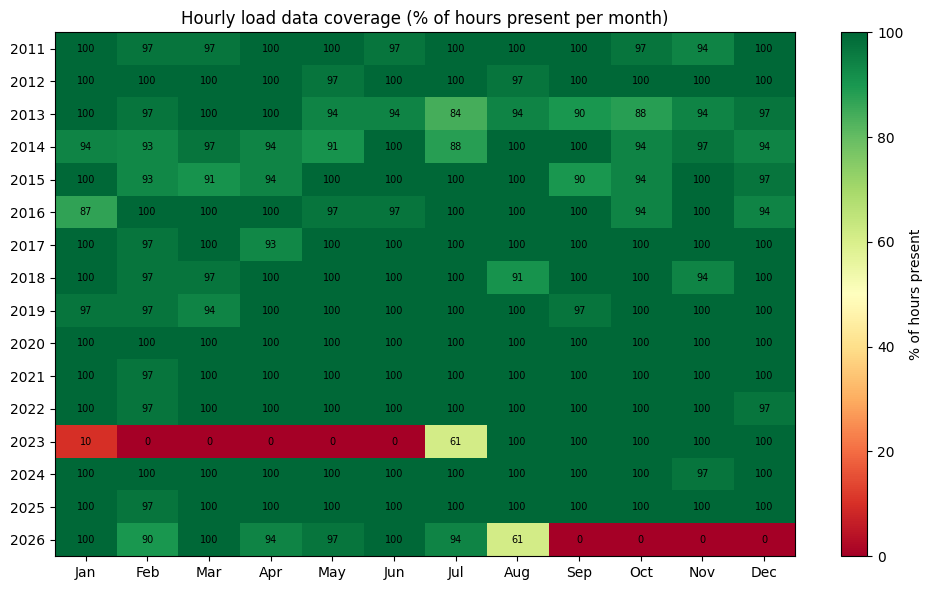

In [6]:
load = pd.read_parquet(config.DATA_RAW / "kptcl.parquet")
load["observed_at"] = pd.to_datetime(load["observed_at"])
load = load.drop_duplicates("observed_at")

hours = load.set_index("observed_at").grid_load_mw.resample("MS").count()
coverage = hours.to_frame("hours")
coverage["year"] = coverage.index.year
coverage["month"] = coverage.index.month
grid = coverage.pivot(index="year", columns="month", values="hours").fillna(0)
expected = grid.columns.to_series().apply(lambda m: pd.Period(f"2020-{m:02d}").days_in_month * 24)
pct = (grid / expected * 100).round(0)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pct, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        ax.text(j, i, f"{pct.iat[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Hourly load data coverage (% of hours present per month)")
fig.colorbar(im, ax=ax, label="% of hours present")
plt.tight_layout()
config.FIGURES.mkdir(parents=True, exist_ok=True)
plt.savefig(config.FIGURES / "01_coverage_heatmap.png", dpi=120)
plt.show()

_What I see: see Result below._

In [7]:
# Months below 90% coverage
low = pct.stack()
low = low[low < 90].rename("coverage_%").reset_index()
print(f"Months below 90% coverage: {len(low)} of {pct.size}")
low

Months below 90% coverage: 16 of 192


,year,month,coverage_%
0,2013,7,84.0
1,2013,10,88.0
2,2014,7,88.0
3,2016,1,87.0
4,2023,1,10.0
5,2023,2,0.0
6,2023,3,0.0
7,2023,4,0.0
8,2023,5,0.0
9,2023,6,0.0


### Step 4.6 — The critical window
*Why:* our question compares **Jul–Dec of 2022, 2023 and 2024**. Check those months specifically.

In [8]:
critical = pct.loc[[2021, 2022, 2023, 2024, 2025], [7, 8, 9, 10, 11, 12]]
critical

month,7,8,9,10,11,12
year,,,,,,
2021,100.0,100.0,100.0,100.0,100.0,100.0
2022,100.0,100.0,100.0,100.0,100.0,97.0
2023,61.0,100.0,100.0,100.0,100.0,100.0
2024,100.0,100.0,100.0,100.0,97.0,100.0
2025,100.0,100.0,100.0,100.0,100.0,100.0


### Step 4.7 — Weather and holiday completeness

In [9]:
wx = pd.read_csv(config.DATA_RAW / "weather_daily.csv", parse_dates=["date"])
print("Weather rows per location:")
print(wx.groupby("location").size().to_string())
print("\nMissing values per column:")
print(wx.isna().sum().to_string())

wxh = pd.read_csv(config.DATA_RAW / "weather_hourly_bengaluru.csv")
print(f"\nBengaluru hourly rows: {len(wxh):,}  missing temperature: {wxh.temperature_2m.isna().sum()}")

hol = pd.read_csv(config.DATA_RAW / "holidays_karnataka.csv", parse_dates=["date"])
print("\nHolidays per year:")
print(hol.groupby(hol.date.dt.year).size().to_string())

Weather rows per location:
location
Belagavi      5710
Bengaluru     5710
Davangere     5710
Hubballi      5710
Kalaburagi    5710
Mandya        5710
Raichur       5710
Tumakuru      5710

Missing values per column:
date                  0
location              0
precipitation_sum     0
temperature_2m_max    0
temperature_2m_min    0



Bengaluru hourly rows: 137,040  missing temperature: 0

Holidays per year:
date
2011    23
2012    23
2013    23
2014    22
2015    24
2016    23
2017    22
2018    23
2019    24
2020    23
2021    23
2022    22
2023    23
2024    23
2025    22
2026    22


## 5. Result
| Expectation | What we found | ✓/✗ |
|---|---|---|
| KPTCL covers 2011-01-01 → 2026-08-19 | Yes, all grid files (daily-summary file ends **2024-08-24**) | ✓ (one surprise) |
| Known gap Feb–Jun 2023 | Gap is **3 Jan – 12 Jul 2023** (slightly longer: Jan 10%, Jul 61%) | ✓ (bigger than expected) |
| Other small gaps | 2013–2016 have a few months at 84–94%; 2017–2025 almost all 100% | ✓ |
| Weather has no gaps | 5,710 days × 8 locations, **0 missing values**; Bengaluru hourly 137,040 rows, 0 missing | ✓ |
| ~20–25 holidays/year | 22–24 per year | ✓ |
| Critical window complete | **Aug–Dec of 2021, 2022, 2023, 2024, 2025: 97–100%** | ✓ |

**Useful surprise:** the 2023 data restarts on **13 July 2023** — 19 days *before* Gruha Jyothi started (1 Aug). That gives us a short pre-scheme baseline inside 2023 itself.

Figure saved: `reports/figures/01_coverage_heatmap.png`

## 6. Caveats
- **No 2023 data from 3 Jan to 12 Jul.** We cannot study the 2023 summer, and the counterfactual model must be trained on data up to **Dec 2022** (plus the 19 July days only as a check).
- `kptcl-daily-summary.parquet` stops at **24 Aug 2024** — fine for context, not usable for 2025–26.
- 2026 data ends **19 Aug 2026** (Aug is partial, Sep–Dec don't exist yet). Not a problem for the 2023 question.
- Weather is **ERA5 reanalysis** (a model of the weather, ~25 km grid), not station measurements. It is standard for this kind of research (Ember, Hunt & Bloomfield use it) but point rainfall can differ locally.
- 7 farm-belt towns are a **sample** of Karnataka's agricultural area, not full coverage. Notebook 06 could test a wider set of points.
- The holiday calendar is from a Python package; regional festivals not on the official list are not included.
- Nothing was filtered or removed in this notebook. Duplicate hours were dropped only for the coverage count (handled properly in Notebook 02).

## 7. Next
**Notebook 02 — Data validation** (Riley: "check vital signs"):
- Duplicates and repeated timestamps in the hourly load
- Impossible values (zero/negative load, sudden jumps, frequency outside 48–52 Hz)
- Station names that change over time (e.g. *Sivasamudra* → *Sivasamudra & Shimsha*)
- Decide and document how to handle gaps (keep as missing, do not fill blindly)
- Save clean tables to `data/processed/`